# Task 2.3: reading the qubit through the buffer

**Answer.** A weak drive $H_Z=\epsilon_Z(a+a^\dagger)$ on the memory makes the two qubit states leak opposite buffer fields:

$$\mathrm{Re}\langle b\rangle_\pm\to\mp b_0,\qquad b_0=\frac{\epsilon_Z}{2\alpha g_2}.$$

At $\alpha=2.1$ and $\epsilon_Z=0.05 g_2$, the simulated field matches $b_0$ to 0.08%. The signal rings at 3.2 MHz and stays within 1% from 0.97 µs onward. Over the 4-µs observation window, the real-field contrast stays within 1% of the linear prediction up to $\epsilon_Z\approx0.6 g_2$. Task 2.4 examines the associated disturbance to the qubit.

**Setup.** Full two-mode model, both loss channels, $\alpha=2.1$, $(N_a,N_b)=(32,12)$. Each state $\lvert\pm\alpha\rangle$ starts with the buffer empty, and the drive switches on at $t=0$. Saved results load by default; set `RERUN=True` to recompute.

In [1]:
from pathlib import Path
import sys, json, io
from contextlib import redirect_stdout
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from research.s2 import notebook_figs as F
show = lambda name, w=1000: display(Image(filename=str(ROOT / "figures" / f"{name}.png"), width=w))
RERUN = False

## 1. The signal and how long it takes

memory state,Re⟨b⟩ / b₀,Im⟨b⟩ / b₀
|+α⟩,-0.9992,+0.2617
|−α⟩,+0.9992,+0.2617


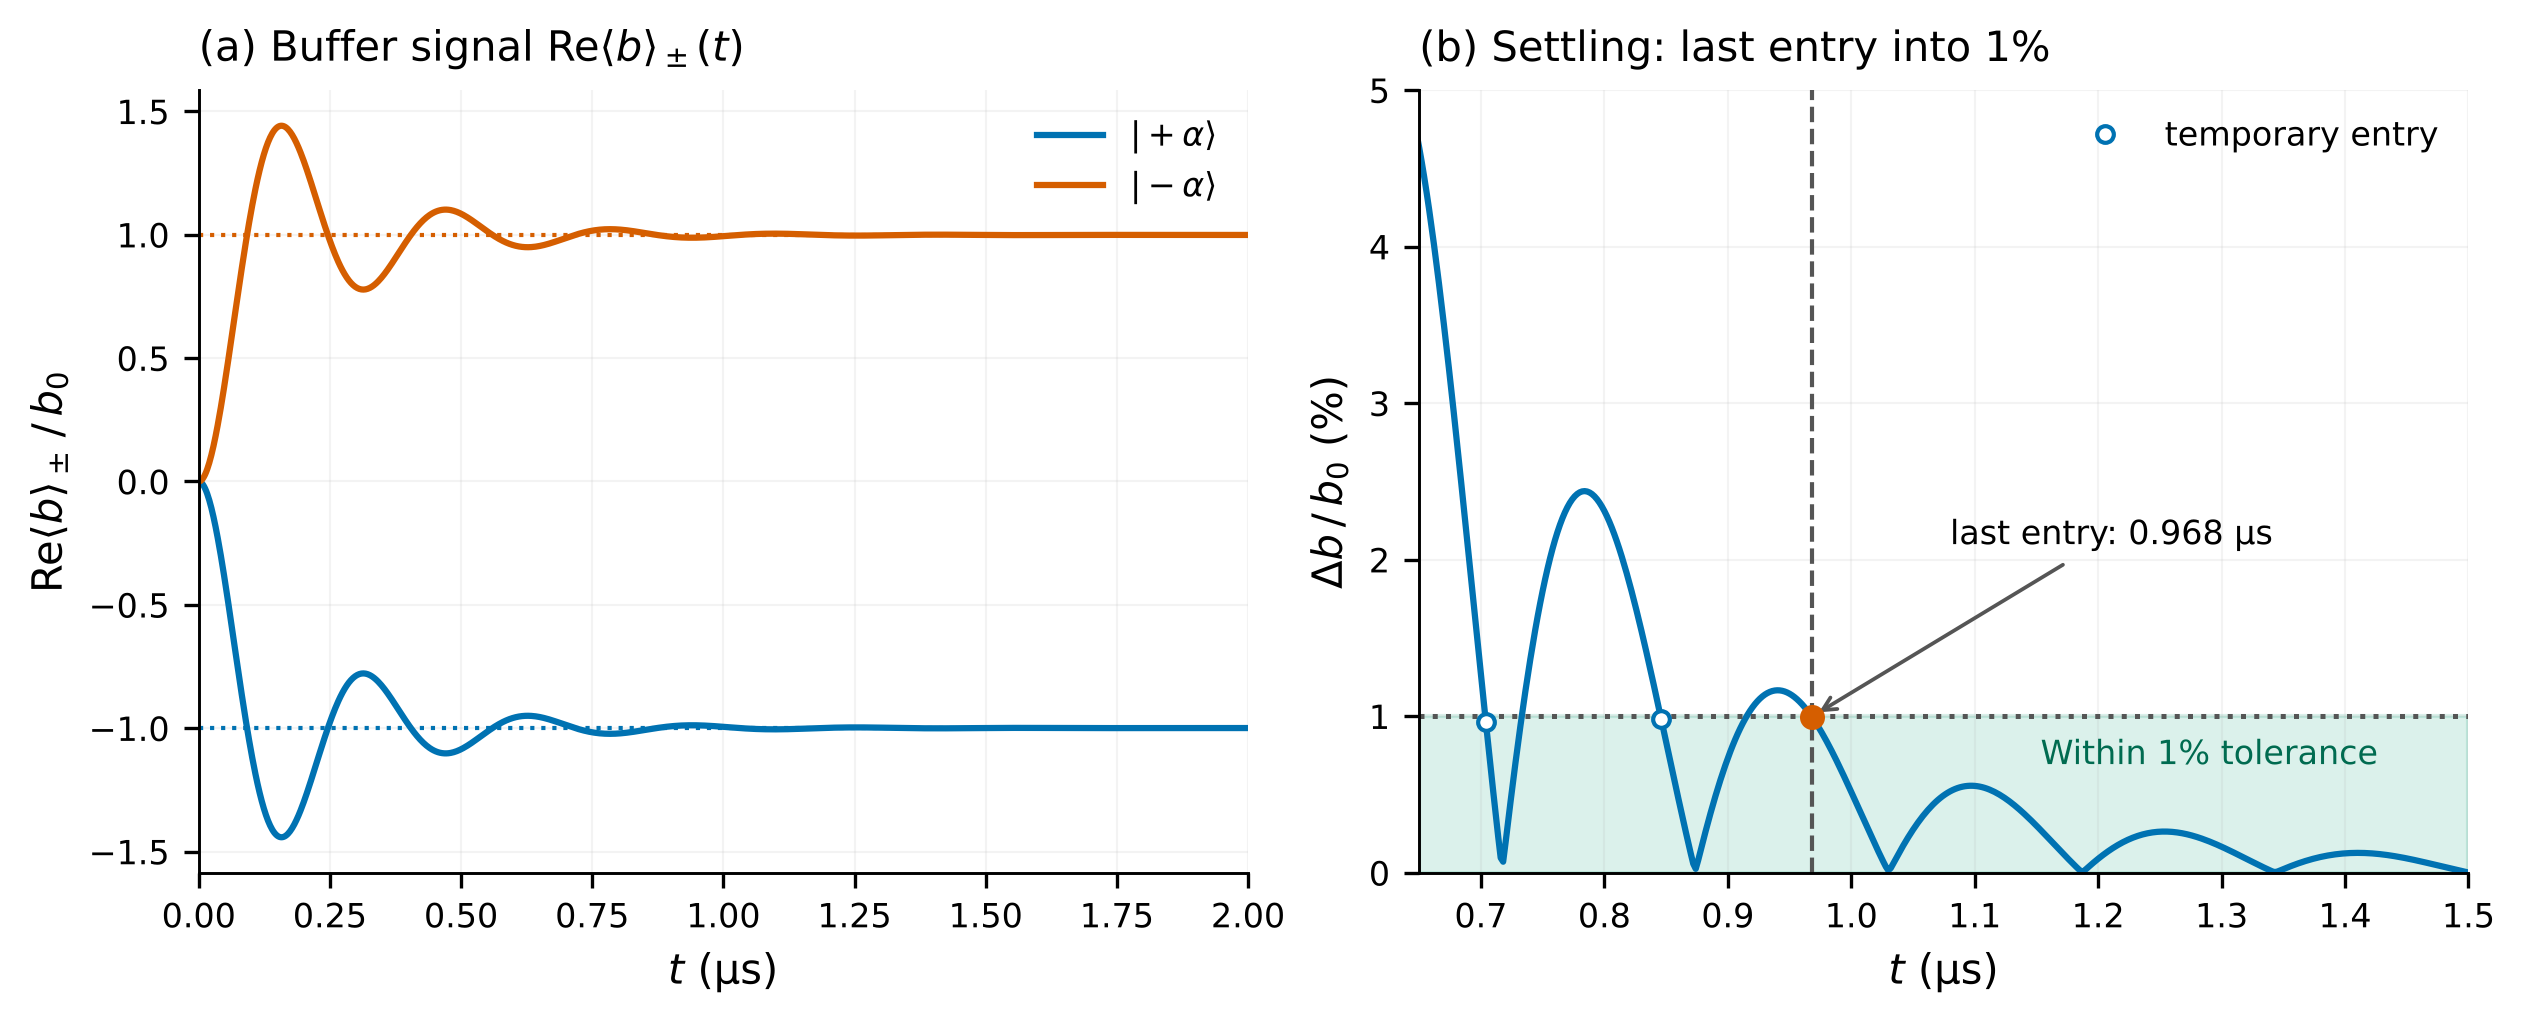

In [2]:
if RERUN:
    from tasks import task_2_3
    with redirect_stdout(io.StringIO()):
        task_2_3.main()
r = json.loads((ROOT / "results/task_2_3.json").read_text())
p = r["configuration"]
s = next(row for row in r["drive_summaries"] if row["drive_ratio"] == p["nominal_drive_ratio"])
b0 = p["epsilon_z"] / (2 * p["alpha"] * p["g2"])
display(pd.DataFrame([
    {"memory state": "|+α⟩", "Re⟨b⟩ / b₀": f"{s['beta_plus'][0] / b0:+.4f}", "Im⟨b⟩ / b₀": f"{s['beta_plus'][1] / b0:+.4f}"},
    {"memory state": "|−α⟩", "Re⟨b⟩ / b₀": f"{s['beta_minus'][0] / b0:+.4f}", "Im⟨b⟩ / b₀": f"{s['beta_minus'][1] / b0:+.4f}"},
]).style.hide(axis="index"))
show("task_2_3_readout")

**Readout signal.** Fields average over 3 to 4 µs; $b_0=\epsilon_Z/(2\alpha g_2)=0.0119$. (a) $\mathrm{Re}\langle b\rangle_\pm/b_0$; dotted lines mark $\mp1$. (b) $\Delta b$ is the larger distance of the two complex fields from their final values. Open circles are temporary entries into the 1% band. The orange dot is the last entry, after which both fields stay inside through 4 µs. Saves are 2 ns apart.

Only $\mathrm{Re}\langle b\rangle$ carries the bit. $\mathrm{Im}\langle b\rangle=+0.26 b_0$ for both states (from memory loss), and does not distinguish them.

**Why it rings.** Near one well, memory and buffer act like two coupled springs:

$$\ddot b+\tfrac{\kappa_b}{2}\dot b+(2g_2\alpha)^2 b=\text{drive}.$$

Since $\kappa_b\lt8g_2\alpha$, this is underdamped. It predicts a 0.319 µs period (3.14 MHz) and a quality factor of 2.5. The simulation gives 0.313 µs and about 2.0, so the spring picture gets the frequency to 2% and the damping to 20%. This is the same physics as the Task 1.1 overshoot. The transient already carries state information. Task 2.4 tests pulse shapes that use this response without waiting for a plateau.

In [3]:
print(f"first peak {s['first_peak_us']:.3f} µs, overshoot {s['overshoot_fraction']:.0%}, "
      f"ring period {s['ring_period_us']:.3f} µs, inside 1% from {s['settling_time_us']:.3f} µs")

first peak 0.158 µs, overshoot 44%, ring period 0.313 µs, inside 1% from 0.968 µs


## 2. How strong can the drive be?

A stronger drive increases the weak-drive signal, but also perturbs the memory. We sweep $\epsilon_Z$ for four cat sizes (`research/s2/readout.py`, 4-µs runs) to locate deviations from the linear contrast prediction. Contrast loss alone does not identify its cause: nonlinear response and memory switching can both contribute.

In [4]:
x = {d["drive_ratio"]: d["real_separation"] / d["leading_separation"] for d in r["drive_summaries"] if d["drive_ratio"]}
rows = []
for a in (1.4, 1.8, 2.1, 2.4):
    d = max(F.load(f"readout_a{a:.2f}_*_T4.json"), key=lambda d: len(d["runs"]))
    e = np.array([x["eps_over_g2"] for x in d["runs"]])
    g = np.array([abs(x["b_ss"][0]) / abs(x["b_ss_linear"]) for x in d["runs"]])
    rows.append({"α": a, "ε_Z / g₂ at 1% loss": f"{np.exp(np.interp(-0.99, -g, np.log(e))):.2f}",
                 "ε_Z / g₂ at 10% loss": f"{np.exp(np.interp(-0.90, -g, np.log(e))):.2f}"})
display(pd.DataFrame(rows).style.hide(axis="index").format({"α": "{:g}"}))
d = max(F.load("readout_a2.10_*_T4.json"), key=lambda d: len(d["runs"]))
ours = next(abs(y["b_ss"][0]) / abs(y["b_ss_linear"]) for y in d["runs"] if y["eps_over_g2"] == 0.05)
print(f"α = 2.1, ε_Z = 0.05 g₂: |Re⟨b⟩| / b₀ = {ours:.6f} (sweep) vs {x[0.05]:.6f} (independent code)")

α,ε_Z / g₂ at 1% loss,ε_Z / g₂ at 10% loss
1.4,0.05,0.25
1.8,0.26,0.75
2.1,0.61,1.25
2.4,1.09,2.00


α = 2.1, ε_Z = 0.05 g₂: |Re⟨b⟩| / b₀ = 0.999164 (sweep) vs 0.999166 (independent code)


**Finite-window contrast.** The table interpolates the drive at which the real-field magnitude $|\mathrm{Re}\bar\beta_+|$ falls 1% and 10% below $b_0$, with $\bar\beta_+$ averaged over the last 5% of each 4-µs run. The 1% crossing rises from about $0.05 g_2$ at $\alpha=1.4$ to $1.1 g_2$ at $\alpha=2.4$. These crossings characterize linearity over this observation window; they do not set a protected-readout operating limit. The two independent codes agree to $3\times10^{-6}$ at $\epsilon_Z=0.05 g_2$.

## Checks

At $\epsilon_Z=0.05 g_2$, the production run is compared with an independent QuTiP BDF solver, tighter tolerances and larger truncations. An 8-µs run checks plateau stability over a longer finite window; it does not establish an infinite-time contrast.

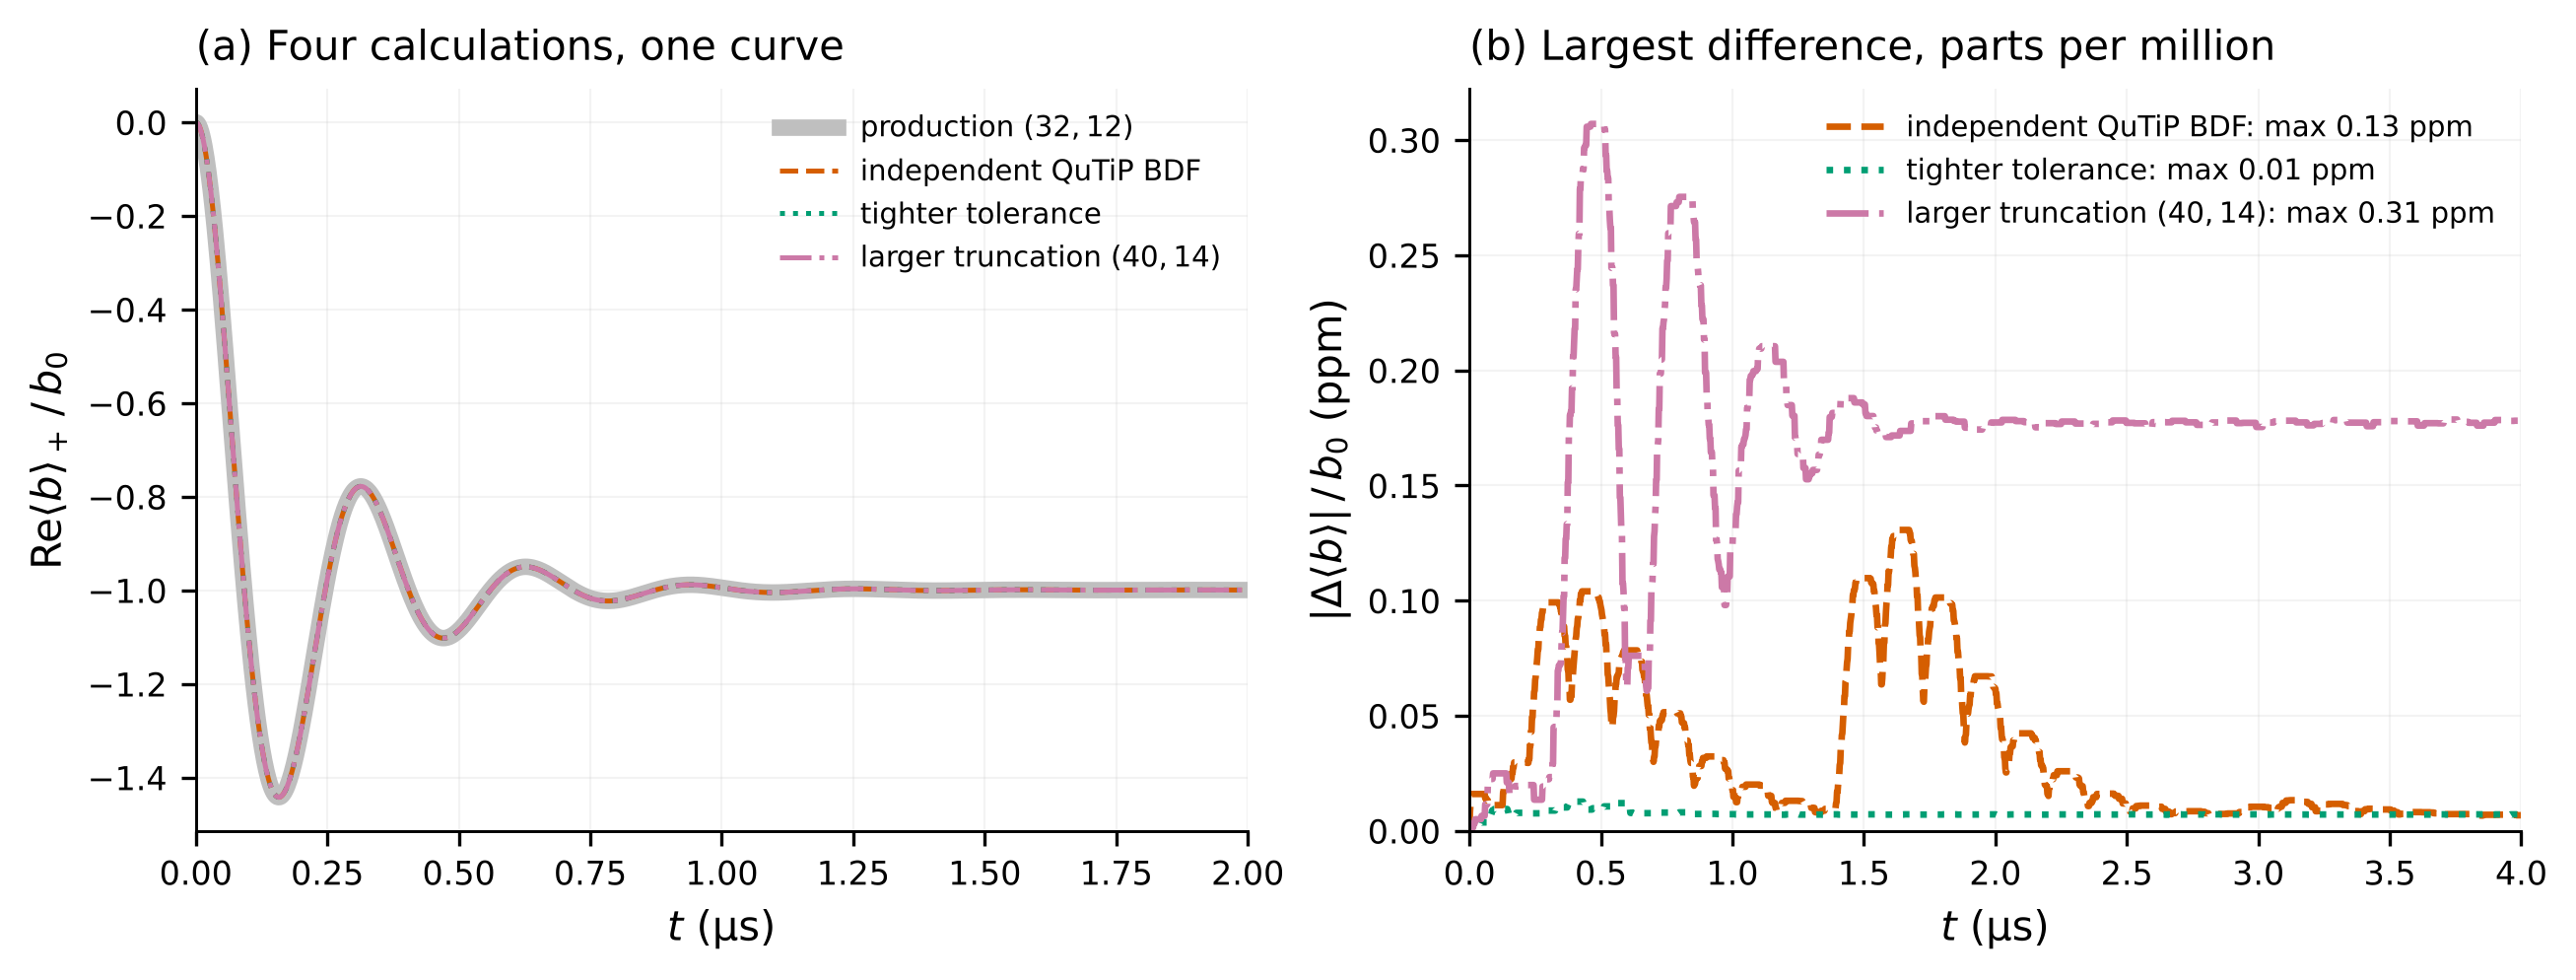

check,max |Δb| / b₀
tighter tolerance,1e-08
independent QuTiP BDF,1e-07
truncation 24×8,1e-05
truncation 40×12,7e-08
truncation 32×14,4e-07
truncation 40×14,3e-07
plateau 3–4 µs vs 7–8 µs,2e-05


In [5]:
show("task_2_3_validation", 900)
v = r["validation"]
display(pd.DataFrame([
    {"check": "tighter tolerance", "max |Δb| / b₀": f"{v['tight_solver_max_field_difference_fraction']:.0e}"},
    {"check": "independent QuTiP BDF", "max |Δb| / b₀": f"{v['independent_qutip']['max_field_error_fraction']:.0e}"},
    *[{"check": f"truncation {c['Na']}×{c['Nb']}", "max |Δb| / b₀": f"{c['max_complex_field_difference_fraction']:.0e}"}
      for c in v["cutoffs"]],
    {"check": "plateau 3–4 µs vs 7–8 µs", "max |Δb| / b₀": f"{v['extended_8us']['plateau_change_fraction']:.0e}"},
]).style.hide(axis="index"))

**Numerical agreement.** (a) Buffer responses from tighter integration, independent QuTiP integration and the larger $(40,14)$ cutoff coincide with the production curve at the plotted scale. (b) Their maximum complex-field differences over both memory states and the full trajectory, divided by $b_0$, are at most 0.31 parts per million. The table also includes the smaller $(24,8)$ cutoff (10.2 ppm) and the change between 3–4 and 7–8 µs plateau averages (24.4 ppm). All satisfy the stated numerical tolerances.

**Result.** The two qubit states give opposite buffer fields of size $\epsilon_Z/(2\alpha g_2)$, confirmed to 0.08% by two independent codes. The signal rings at 3.2 MHz, settles in 0.97 µs, and stays within 1% of the linear prediction up to $\epsilon_Z\approx0.6 g_2$ at $\alpha=2.1$ over the 4-µs window.

Limits: this is the mean field. A single-shot fidelity requires output-noise statistics and a decision rule. Task 2.4 compares pulses using a conditional-mean, shot-noise reference; that comparison is not a simulated single-shot fidelity. The leading estimate follows [Réglade et al., Supplement S8.5](https://arxiv.org/abs/2307.06617); derivations are in [the readout report](../docs/task_2.md#23--read-the-memory-bit-through-the-buffer).